# Problema 1 — Rede Adaline para Classificação de Retornos de Radares Ionosféricos

**Dataset:** UCI Ionosphere (351 amostras, 34 atributos contínuos, classes `good` (+1) e `bad` (-1)).

In [6]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_squared_error
)

SEED = 42

## 1. Preparação dos Dados

- Carregamento do dataset e recodificação bipolar (`g` → `+1`, `b` → `-1`).
- Verificação de valores ausentes e remoção de atributos constantes.
- Divisão estratificada (80% treino / 20% teste) e padronização *Z-score* ajustada apenas no treino (evitando vazamento de dados).

In [7]:
data_path = Path("data/ionosphere/ionosphere.data")
if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/ionosphere/ionosphere.data"
    urllib.request.urlretrieve(url, data_path)

df = pd.read_csv(data_path, header=None)
X = df.iloc[:, :-1].copy()
y = df.iloc[:, -1].map({"g": 1, "b": -1}).to_numpy()

missing = X.isna().sum().sum()
const_cols = X.columns[X.nunique() <= 1].tolist()
X = X.drop(columns=const_cols)

print(f"Amostras: {len(df)} | Valores ausentes: {missing}")
print(f"Atributos constantes removidos: {const_cols} | Atributos restantes: {X.shape[1]}")
print(f"Distribuição de classes -> good (+1): {(y == 1).sum()}, bad (-1): {(y == -1).sum()}")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X.to_numpy(), y, test_size=0.2, stratify=y, random_state=SEED
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

Amostras: 351 | Valores ausentes: 0
Atributos constantes removidos: [1] | Atributos restantes: 33
Distribuição de classes -> good (+1): 225, bad (-1): 126


## 2. Rede Adaline 

A Rede Adaline minimiza o erro quadrático médio (MSE) sobre a saída linear $\hat{y} = \mathbf{w}^T\mathbf{x} + b$ via Regra Delta (LMS). Utilizamos `SGDRegressor(loss='squared_error', penalty=None, learning_rate='constant')` atualizado época a época (`partial_fit`) por $N = 200$ épocas.

In [8]:
def train_adaline(X_tr, y_tr, eta, epochs=200, seed=SEED):
    model = SGDRegressor(
        loss="squared_error",
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        shuffle=True,
        random_state=seed,
    )
    rng = np.random.default_rng(seed)
    losses = []
    for _ in range(epochs):
        idx = rng.permutation(len(X_tr))
        model.partial_fit(X_tr[idx], y_tr[idx])
        preds = model.predict(X_tr)
        if not np.all(np.isfinite(preds)):
            losses.append(np.nan)
            break
        loss = 0.5 * mean_squared_error(y_tr, preds)
        losses.append(loss)
        if loss > 1e6:
            break
    return model, losses

etas = [1e-4, 1e-3, 1e-2, 5e-2, 1e-1]
results = {}

for eta in etas:
    model, losses = train_adaline(X_train, y_train, eta)
    converged = len(losses) == 200 and np.isfinite(losses[-1])
    results[eta] = {"model": model, "losses": losses, "converged": converged}
    status = f"Loss final = {losses[-1]:.5f} (std últimas 20 épocas = {np.std(losses[-20:]):.2e})" if converged else f"Divergiu na época {len(losses)}"
    print(f"eta = {eta:<6g} | {status}")

eta = 0.0001 | Loss final = 0.19066 (std últimas 20 épocas = 2.21e-04)
eta = 0.001  | Loss final = 0.18511 (std últimas 20 épocas = 1.77e-04)
eta = 0.01   | Loss final = 0.23150 (std últimas 20 épocas = 1.46e-02)
eta = 0.05   | Divergiu na época 3
eta = 0.1    | Divergiu na época 1


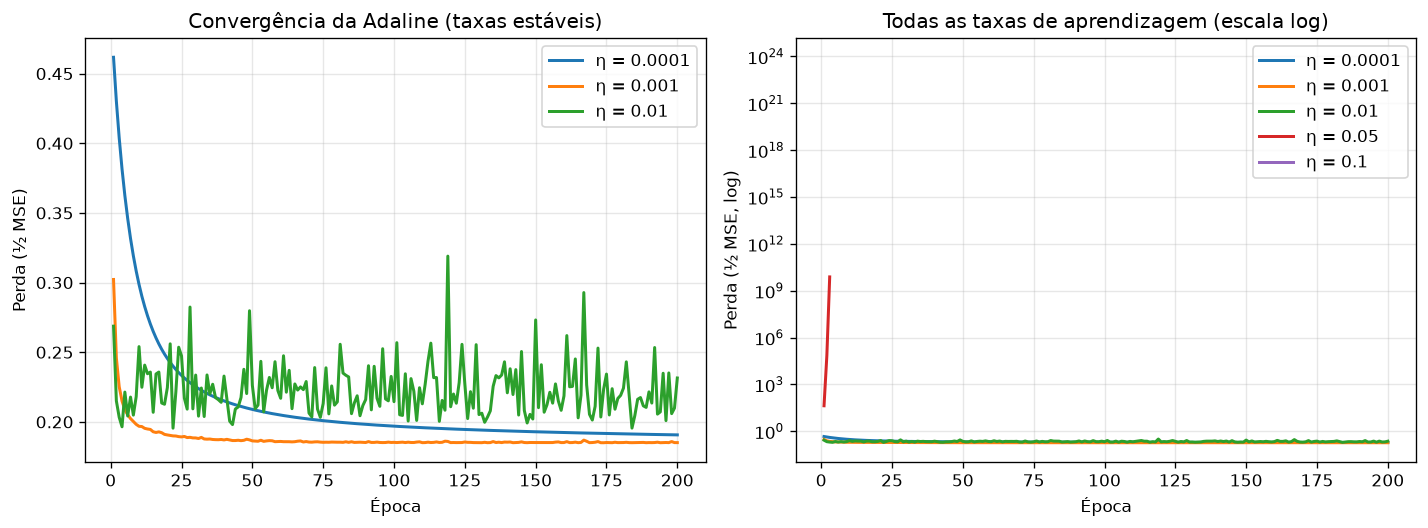

Melhor taxa de aprendizagem selecionada: η = 0.001 (loss final = 0.18511)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for eta in etas:
    r = results[eta]
    if r["converged"]:
        axes[0].plot(range(1, len(r["losses"]) + 1), r["losses"], label=f"η = {eta:g}", lw=1.8)
axes[0].set(title="Convergência da Adaline (taxas estáveis)", xlabel="Época", ylabel="Perda (½ MSE)")
axes[0].legend()

for eta in etas:
    r = results[eta]
    vals = [v for v in r["losses"] if np.isfinite(v)]
    axes[1].plot(range(1, len(vals) + 1), vals, label=f"η = {eta:g}", lw=1.8)
axes[1].set_yscale("log")
axes[1].set(title="Todas as taxas de aprendizagem (escala log)", xlabel="Época", ylabel="Perda (½ MSE, log)")
axes[1].legend()

plt.tight_layout()
plt.show()

stable_etas = [e for e in etas if results[e]["converged"]]
best_eta = min(stable_etas, key=lambda e: results[e]["losses"][-1])
print(f"Melhor taxa de aprendizagem selecionada: η = {best_eta:g} (loss final = {results[best_eta]['losses'][-1]:.5f})")

## 3. Avaliação no Conjunto de Teste

Classificação binária via função sinal ($\text{sign}(\hat{y}) \in \{-1, +1\}$), matriz de confusão e métricas de desempenho.

Acurácia : 0.9155
Precisão : 0.8846 (classe good / +1)
Recall   : 1.0000 (classe good / +1)
F1-score : 0.9388 (classe good / +1)

              precision    recall  f1-score   support

    bad (-1)     1.0000    0.7600    0.8636        25
   good (+1)     0.8846    1.0000    0.9388        46

    accuracy                         0.9155        71
   macro avg     0.9423    0.8800    0.9012        71
weighted avg     0.9252    0.9155    0.9123        71



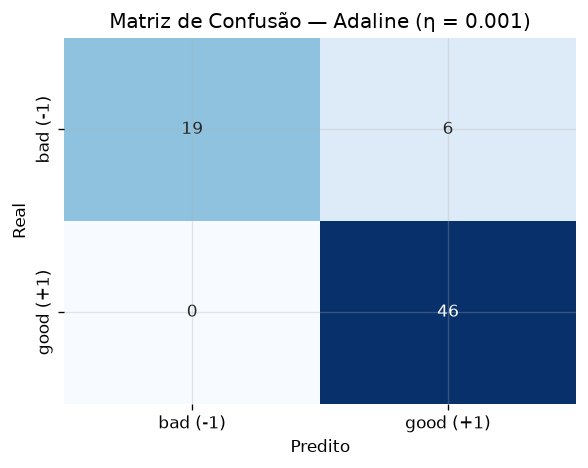

In [10]:
best_model = results[best_eta]["model"]
y_pred = np.where(best_model.predict(X_test) >= 0, 1, -1)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1)
rec = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])

print(f"Acurácia : {acc:.4f}")
print(f"Precisão : {prec:.4f} (classe good / +1)")
print(f"Recall   : {rec:.4f} (classe good / +1)")
print(f"F1-score : {f1:.4f} (classe good / +1)\n")
print(classification_report(y_test, y_pred, labels=[-1, 1], target_names=["bad (-1)", "good (+1)"], digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["bad (-1)", "good (+1)"],
    yticklabels=["bad (-1)", "good (+1)"], ax=ax
)
ax.set(title=f"Matriz de Confusão — Adaline (η = {best_eta:g})", xlabel="Predito", ylabel="Real")
plt.tight_layout()
plt.show()